# Classificação de Placas de Trânsito com Transfer Learning (MobileNetV2)

Este notebook treina um modelo de classificação de imagens usando **Transfer Learning** com **MobileNetV2** no PyTorch.

## Etapas:
1. Setup inicial e verificação de GPU
2. Pré-processamento e carregamento dos dados
3. Construção do modelo com MobileNetV2 pré-treinado
4. Treinamento (feature extraction)
5. Fine-tuning
6. Avaliação final (métricas, matriz de confusão, exemplos)
7. Salvamento e download do modelo

## Dataset

O dataset utilizado é o **GTSRB (German Traffic Sign Recognition Benchmark)**, um dos mais conhecidos para classificação de placas de trânsito. Ele contém **43 classes** diferentes de placas, com mais de **50.000 imagens** no total.

### Estrutura do Dataset
- **Treino**: ~39.000 imagens organizadas em subpastas por classe (0 a 42)
- **Teste**: ~12.600 imagens (organizadas via CSV)

### Etapas de Preparação
1. Download do dataset via Kaggle API
2. Organização das imagens de teste em subpastas por classe
3. Aplicação de transformações (redimensionamento, augmentação, normalização)

In [1]:
pip install kaggle

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle//
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d hingridsouza/gtsrb-dataset

Dataset URL: https://www.kaggle.com/datasets/hingridsouza/gtsrb-dataset
License(s): unknown
100% 306M/306M [00:03<00:00, 105MB/s]



In [5]:
!unzip gtsrb-dataset.zip

A saída de streaming foi truncada nas últimas 5000 linhas.
  inflating: GTSRB/Train/5/00005_00053_00010.png  
  inflating: GTSRB/Train/5/00005_00053_00011.png  
  inflating: GTSRB/Train/5/00005_00053_00012.png  
  inflating: GTSRB/Train/5/00005_00053_00013.png  
  inflating: GTSRB/Train/5/00005_00053_00014.png  
  inflating: GTSRB/Train/5/00005_00053_00015.png  
  inflating: GTSRB/Train/5/00005_00053_00016.png  
  inflating: GTSRB/Train/5/00005_00053_00017.png  
  inflating: GTSRB/Train/5/00005_00053_00018.png  
  inflating: GTSRB/Train/5/00005_00053_00019.png  
  inflating: GTSRB/Train/5/00005_00053_00020.png  
  inflating: GTSRB/Train/5/00005_00053_00021.png  
  inflating: GTSRB/Train/5/00005_00053_00022.png  
  inflating: GTSRB/Train/5/00005_00053_00023.png  
  inflating: GTSRB/Train/5/00005_00053_00024.png  
  inflating: GTSRB/Train/5/00005_00053_00025.png  
  inflating: GTSRB/Train/5/00005_00053_00026.png  
  inflating: GTSRB/Train/5/00005_00053_00027.png  
  inflating: GTSRB/Trai

In [6]:
import os
import shutil
import pandas as pd

csv_file = "GTSRB/Test.csv"
test_dir = "GTSRB/Test"
output_dir = "GTSRB/test_organized"

df = pd.read_csv(csv_file)

for _, row in df.iterrows():

    class_id = str(row["ClassId"])

    image_name = os.path.basename(row["Path"])

    class_folder = os.path.join(output_dir, class_id)
    os.makedirs(class_folder, exist_ok=True)

    src = os.path.join(test_dir, image_name)
    dst = os.path.join(class_folder, image_name)

    shutil.copy2(src, dst)

In [7]:
cd GTSRB

/content/GTSRB


In [8]:
!rm -rf Test

In [9]:
!mv test_organized Test

In [10]:
import shutil

shutil.make_archive('/content/GTSRB', 'zip', '/content/GTSRB')

'/content/GTSRB.zip'

In [11]:
from google.colab import files

files.download('/content/GTSRB.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 1. Setup Inicial

In [ ]:
# Montar Google Drive (opcional - para carregar dataset diretamente)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('Google Drive montado em /content/drive')
except ImportError:
    print('Ambiente local detectado. Monte o dataset manualmente ou ajuste os caminhos.')

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from sklearn.metrics import classification_report, confusion_matrix

import seaborn as sns
import os
import random
from pathlib import Path

print('Todas as bibliotecas foram importadas com sucesso.')

Todas as bibliotecas foram importadas com sucesso.


In [ ]:
# Verificar GPU disponivel
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo utilizado: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memoria: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')

Dispositivo utilizado: cuda
GPU: Tesla T4
Memoria: 15.64 GB


In [ ]:
# Hiperparametros (ajustaveis)
NUM_CLASSES = 43          # <<< Altere conforme seu dataset
BATCH_SIZE = 32
EPOCHS_FE = 30           # epocas para feature extraction
EPOCHS_FT = 20            # epocas para fine-tuning
LR_FE = 1e-3             # learning rate para feature extraction
LR_FT_BACKBONE = 1e-5    # learning rate para backbone no fine-tuning
LR_FT_CLASSIFIER = 1e-4  # learning rate para classifier no fine-tuning

DATA_DIR = 'GTSRB'  # diretorio raiz contendo train/ e val/ ou test/

---
## 2. Pre-processamento dos Dados

Aplicamos transformações de **data augmentation** no conjunto de treino para melhorar a generalização do modelo:
- Redimensionamento aleatório e recorte centralizado
- Rotação horizontal aleatória
- Normalização com as médias e desvios padrão do ImageNet

Para validação, apenas redimensionamos e centralizamos a imagem, sem augmentation.

In [ ]:
cd ./

/root


In [ ]:
# Transformacoes para treino (com aumento de dados)
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Transformacoes para validacao (apenas redimensionamento e centralizacao)
val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [ ]:
# Verificar se o dataset existe; se nao, exibir instrucoes
train_dir = os.path.join(DATA_DIR, 'Train')
val_dir = os.path.join(DATA_DIR, 'Val') if os.path.isdir(os.path.join(DATA_DIR, 'val')) else os.path.join(DATA_DIR, 'Test')

if not os.path.isdir(train_dir):
    print('=' * 60)
    print('DATASET NAO ENCONTRADO!')
    print('=' * 60)
    print('Certifique-se de que a estrutura de pastas seja:')
    print('  data/')
    print('    train/')
    print('      classe_0/')
    print('      classe_1/')
    print('      ...')
    print('    val/')
    print('      classe_0/')
    print('      classe_1/')
    print('      ...')
    print()
    print('Opcoes de upload:')
    print('  1. Faca upload manual pela interface do Colab (pastas)')
    print('  2. Monte o Google Drive e copie o dataset:')
    print('     !cp -r /content/drive/MyDrive/seu_dataset/* data/')
    print('  3. Ajuste DATA_DIR para o caminho correto')
    print('=' * 60)
    raise FileNotFoundError(f'Dataset nao encontrado em {train_dir}')
else:
    print(f'Treino: {train_dir}')
    print(f'Validacao: {val_dir}')

Treino: GTSRB/Train
Validacao: GTSRB/Test


In [ ]:
# Carregar datasets com ImageFolder
train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset = datasets.ImageFolder(val_dir, transform=val_transforms)

# Criar DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Mapeamento indice -> nome da classe
class_names = train_dataset.classes
print(f'Classes encontradas: {len(class_names)}')
print(f'Imagens de treino: {len(train_dataset)}')
print(f'Imagens de validacao: {len(val_dataset)}')

Classes encontradas: 43
Imagens de treino: 39209
Imagens de validacao: 12630


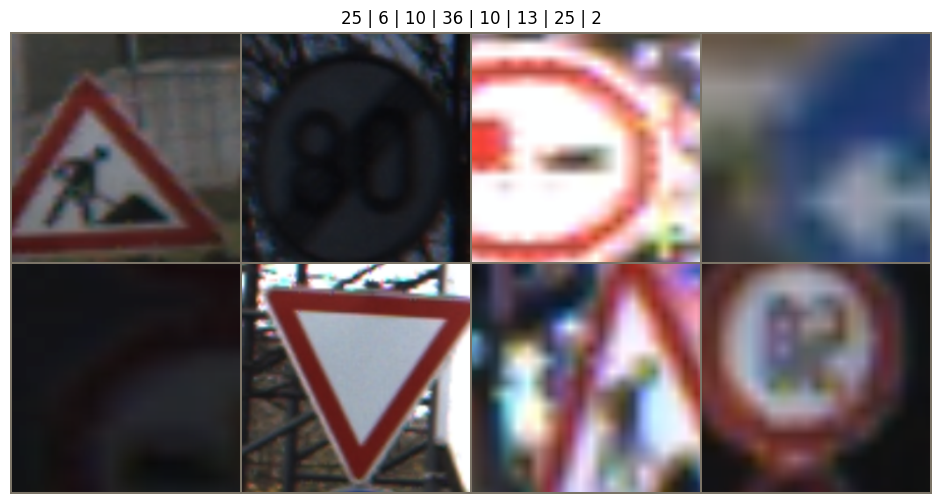

In [ ]:
import torchvision
# Visualizar algumas amostras do dataset
def imshow(inp, title=None):
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title:
        plt.title(title)
    plt.axis('off')

inputs, classes = next(iter(train_loader))
out = torchvision.utils.make_grid(inputs[:8], nrow=4)

plt.figure(figsize=(12, 6))
imshow(out, title=' | '.join([class_names[c] for c in classes[:8]]))
plt.show()

---
## 3. Construção do Modelo (MobileNetV2)

Utilizamos a **MobileNetV2** pré-treinada no ImageNet como extrator de características. A estratégia é:
1. **Feature Extraction** (fases iniciais): congelar o backbone e treinar apenas o classificador
2. **Fine-Tuning** (fase posterior): descongelar parcialmente o backbone para ajuste fino

O classificador original da MobileNetV2 é substituído por uma nova cabeça com **43 classes** (número de placas no GTSRB).

In [ ]:
# Carregar MobileNetV2 pre-treinado
model = models.mobilenet_v2(pretrained=True)

# Congelar todas as camadas do backbone (feature extraction)
for param in model.features.parameters():
    param.requires_grad = False

# Substituir o classificador para o numero de classes desejado
model.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(model.last_channel, 512),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(512, NUM_CLASSES)
)

model = model.to(device)
print(f'Modelo MobileNetV2 carregado. Classificador ajustado para {NUM_CLASSES} classes.')

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 154MB/s]

Modelo MobileNetV2 carregado. Classificador ajustado para 43 classes.


In [ ]:
# Funcao de custo e otimizador (apenas para o classifier na fase de feature extraction)
criterion = nn.CrossEntropyLoss()
optimizer_fe = optim.Adam(model.classifier.parameters(), lr=LR_FE)

# Scheduler opcional: reduz learning rate quando a metrica estagnar
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer_fe, mode='min', factor=0.5, patience=2)

---
## 4. Funcoes de Treinamento e Validacao

Definimos duas funções auxiliares:
- **`train_one_epoch`**: executa uma época de treinamento com forward/backward/optimization
- **`validate`**: avalia o modelo no conjunto de validação sem calcular gradientes

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total = 0

    pbar = tqdm(loader, desc='Treinando')
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data).item()
        total += inputs.size(0)

        pbar.set_postfix({'loss': f'{loss.item():.4f}', 'acc': f'{running_corrects/total:.4f}'})

    epoch_loss = running_loss / total
    epoch_acc = running_corrects / total
    return epoch_loss, epoch_acc

In [ ]:
def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc='Validando'):
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data).item()
            total += inputs.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_corrects / total
    return epoch_loss, epoch_acc

---
## 5. Loop de Treinamento Principal (Feature Extraction)

Nesta fase, apenas o **classificador** (head) é treinado. O backbone da MobileNetV2 permanece congelado.
- Otimizador: Adam com learning rate de `1e-3`
- Scheduler: ReduceLROnPlateau (reduz LR quando a loss estagna)
- Número de épocas: 30

In [ ]:
import copy
best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print('=' * 60)
print('FASE 1: Feature Extraction')
print(f'Epocas: {EPOCHS_FE} | LR: {LR_FE}')
print('=' * 60)

for epoch in range(1, EPOCHS_FE + 1):
    print(f'\nEpoca {epoch}/{EPOCHS_FE}')
    print('-' * 40)

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer_fe, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f'Treino  - Loss: {train_loss:.4f} | Acc: {train_acc:.4f}')
    print(f'Val     - Loss: {val_loss:.4f} | Acc: {val_acc:.4f}')

    if val_acc > best_acc:
        best_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        print(f'*** Novo melhor modelo salvo (acc: {best_acc:.4f}) ***')

print(f'\nFase 1 concluida. Melhor acuracia de validacao: {best_acc:.4f}')

FASE 1: Feature Extraction
Epocas: 30 | LR: 0.001

Epoca 1/30
----------------------------------------


Treinando:   0%|          | 0/1226 [00:00<?, ?it/s]

Validando:   0%|          | 0/395 [00:00<?, ?it/s]

Treino  - Loss: 1.7874 | Acc: 0.4724
Val     - Loss: 1.1320 | Acc: 0.6226
*** Novo melhor modelo salvo (acc: 0.6226) ***

Epoca 2/30
----------------------------------------


Treinando:   0%|          | 0/1226 [00:00<?, ?it/s]

Validando:   0%|          | 0/395 [00:00<?, ?it/s]

... (81 outputs left out)

Treino  - Loss: 0.9507 | Acc: 0.6974
Val     - Loss: 0.8319 | Acc: 0.7363

Epoca 30/30
----------------------------------------


Treinando:   0%|          | 0/1226 [00:00<?, ?it/s]

Validando:   0%|          | 0/395 [00:00<?, ?it/s]

Treino  - Loss: 0.9471 | Acc: 0.6997
Val     - Loss: 0.8116 | Acc: 0.7438
*** Novo melhor modelo salvo (acc: 0.7438) ***

Fase 1 concluida. Melhor acuracia de validacao: 0.7438


- 1h 40min

---
## 6. Fine-Tuning (Afinamento)

Agora descongelamos as **últimas 25 camadas** do backbone para ajuste fino com learning rates menores:
- Backbone: `1e-5` (ajuste sutil dos pesos pré-treinados)
- Classificador: `1e-4` (mais liberdade para adaptação)
- Número de épocas: 20

In [ ]:
# Descongelar as ultimas 25 camadas do backbone para fine-tuning
for param in model.features[-25:].parameters():
    param.requires_grad = True

# Carregar os melhores pesos da fase anterior
model.load_state_dict(best_model_wts)

# Otimizador com grupos de parametros com learning rates diferentes
optimizer_ft = optim.Adam([
    {'params': model.features[-25:].parameters(), 'lr': LR_FT_BACKBONE},
    {'params': model.classifier.parameters(), 'lr': LR_FT_CLASSIFIER}
])

# Scheduler para fine-tuning
scheduler_ft = optim.lr_scheduler.ReduceLROnPlateau(optimizer_ft, mode='min', factor=0.5, patience=2)

print(f'Ultimas 25 camadas do backbone descongeladas.')
print(f'LR backbone: {LR_FT_BACKBONE} | LR classifier: {LR_FT_CLASSIFIER}')

Ultimas 25 camadas do backbone descongeladas.
LR backbone: 1e-05 | LR classifier: 0.0001


In [ ]:
best_acc_ft = 0.0
best_model_wts_ft = copy.deepcopy(model.state_dict())

print('=' * 60)
print('FASE 2: Fine-Tuning')
print(f'Epocas: {EPOCHS_FT} | LR backbone: {LR_FT_BACKBONE} | LR classifier: {LR_FT_CLASSIFIER}')
print('=' * 60)

patience = 5
counter = 0

for epoch in range(1, EPOCHS_FT + 1):
    print(f'\nEpoca {epoch}/{EPOCHS_FT}')
    print('-' * 40)

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer_ft, device)
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    scheduler_ft.step(val_loss)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f'Treino  - Loss: {train_loss:.4f} | Acc: {train_acc:.4f}')
    print(f'Val     - Loss: {val_loss:.4f} | Acc: {val_acc:.4f}')

    if val_acc > best_acc_ft:
        best_acc_ft = val_acc
        best_model_wts_ft = copy.deepcopy(model.state_dict())
        counter = 0
        print(f'*** Novo melhor modelo salvo (acc: {best_acc_ft:.4f}) ***')
    else:
        counter += 1
        print(f'Sem melhora: {counter}/{patience}')

    if counter >= patience:
        print(f'\nEarly Stopping na época {epoch}')
        break

print(f'\nFine-tuning concluido. Melhor acuracia de validacao: {best_acc_ft:.4f}')

FASE 2: Fine-Tuning
Epocas: 20 | LR backbone: 1e-05 | LR classifier: 0.0001

Epoca 1/20
----------------------------------------


Treinando:   0%|          | 0/1226 [00:00<?, ?it/s]

Validando:   0%|          | 0/395 [00:00<?, ?it/s]

Treino  - Loss: 0.7214 | Acc: 0.7689
Val     - Loss: 0.5189 | Acc: 0.8360
*** Novo melhor modelo salvo (acc: 0.8360) ***

Epoca 2/20
----------------------------------------


Treinando:   0%|          | 0/1226 [00:00<?, ?it/s]

Validando:   0%|          | 0/395 [00:00<?, ?it/s]

... (51 outputs left out)

Treino  - Loss: 0.1820 | Acc: 0.9408
Val     - Loss: 0.2716 | Acc: 0.9363

Epoca 20/20
----------------------------------------


Treinando:   0%|          | 0/1226 [00:00<?, ?it/s]

Validando:   0%|          | 0/395 [00:00<?, ?it/s]

Treino  - Loss: 0.1770 | Acc: 0.9404
Val     - Loss: 0.2608 | Acc: 0.9389
*** Novo melhor modelo salvo (acc: 0.9389) ***

Fine-tuning concluido. Melhor acuracia de validacao: 0.9389


- 1h 25min

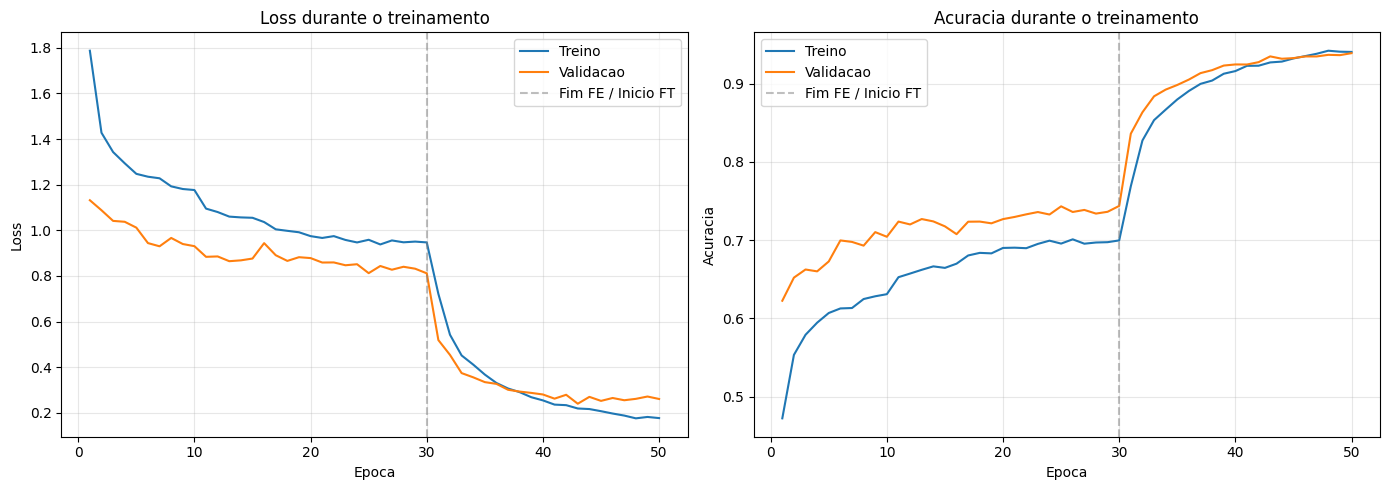

In [ ]:
# Plotar graficos de loss e acuracia
epochs_fe = EPOCHS_FE
epochs_ft = EPOCHS_FT

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(1, len(history['train_loss']) + 1), history['train_loss'], label='Treino')
ax1.plot(range(1, len(history['val_loss']) + 1), history['val_loss'], label='Validacao')
ax1.axvline(x=epochs_fe, color='gray', linestyle='--', alpha=0.5, label='Fim FE / Inicio FT')
ax1.set_xlabel('Epoca')
ax1.set_ylabel('Loss')
ax1.set_title('Loss durante o treinamento')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(range(1, len(history['train_acc']) + 1), history['train_acc'], label='Treino')
ax2.plot(range(1, len(history['val_acc']) + 1), history['val_acc'], label='Validacao')
ax2.axvline(x=epochs_fe, color='gray', linestyle='--', alpha=0.5, label='Fim FE / Inicio FT')
ax2.set_xlabel('Epoca')
ax2.set_ylabel('Acuracia')
ax2.set_title('Acuracia durante o treinamento')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Avaliacao Final

Com o modelo treinado, avaliamos seu desempenho no conjunto de teste:
- **Relatório de classificação** (precisão, recall, f1-score por classe)
- **Matriz de confusão** para visualizar acertos e erros
- **Exemplos visuais** de predições corretas e incorretas

In [ ]:
# Carregar o melhor modelo do fine-tuning e avaliar
model.load_state_dict(best_model_wts_ft)
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(val_loader, desc='Avaliando'):
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print('\n=== Relatorio de Classificacao ===')
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

Avaliando:   0%|          | 0/395 [00:00<?, ?it/s]


=== Relatorio de Classificacao ===
              precision    recall  f1-score   support

           0     1.0000    0.8667    0.9286        60
           1     0.9786    0.9528    0.9655       720
          10     0.9970    1.0000    0.9985       660
          11     0.9099    0.9857    0.9463       420
          12     0.9941    0.9826    0.9883       690
          13     0.9863    0.9986    0.9924       720
          14     1.0000    1.0000    1.0000       270
          15     1.0000    0.9952    0.9976       210
          16     1.0000    0.9933    0.9967       150
          17     0.9970    0.9167    0.9551       360
          18     1.0000    0.8692    0.9300       390
          19     0.6353    0.9000    0.7448        60
           2     0.8993    0.9880    0.9416       750
          20     0.8356    0.6778    0.7485        90
          21     0.7525    0.8444    0.7958        90
          22     0.9785    0.7583    0.8545       120
          23     0.8605    0.9867    0.9193  

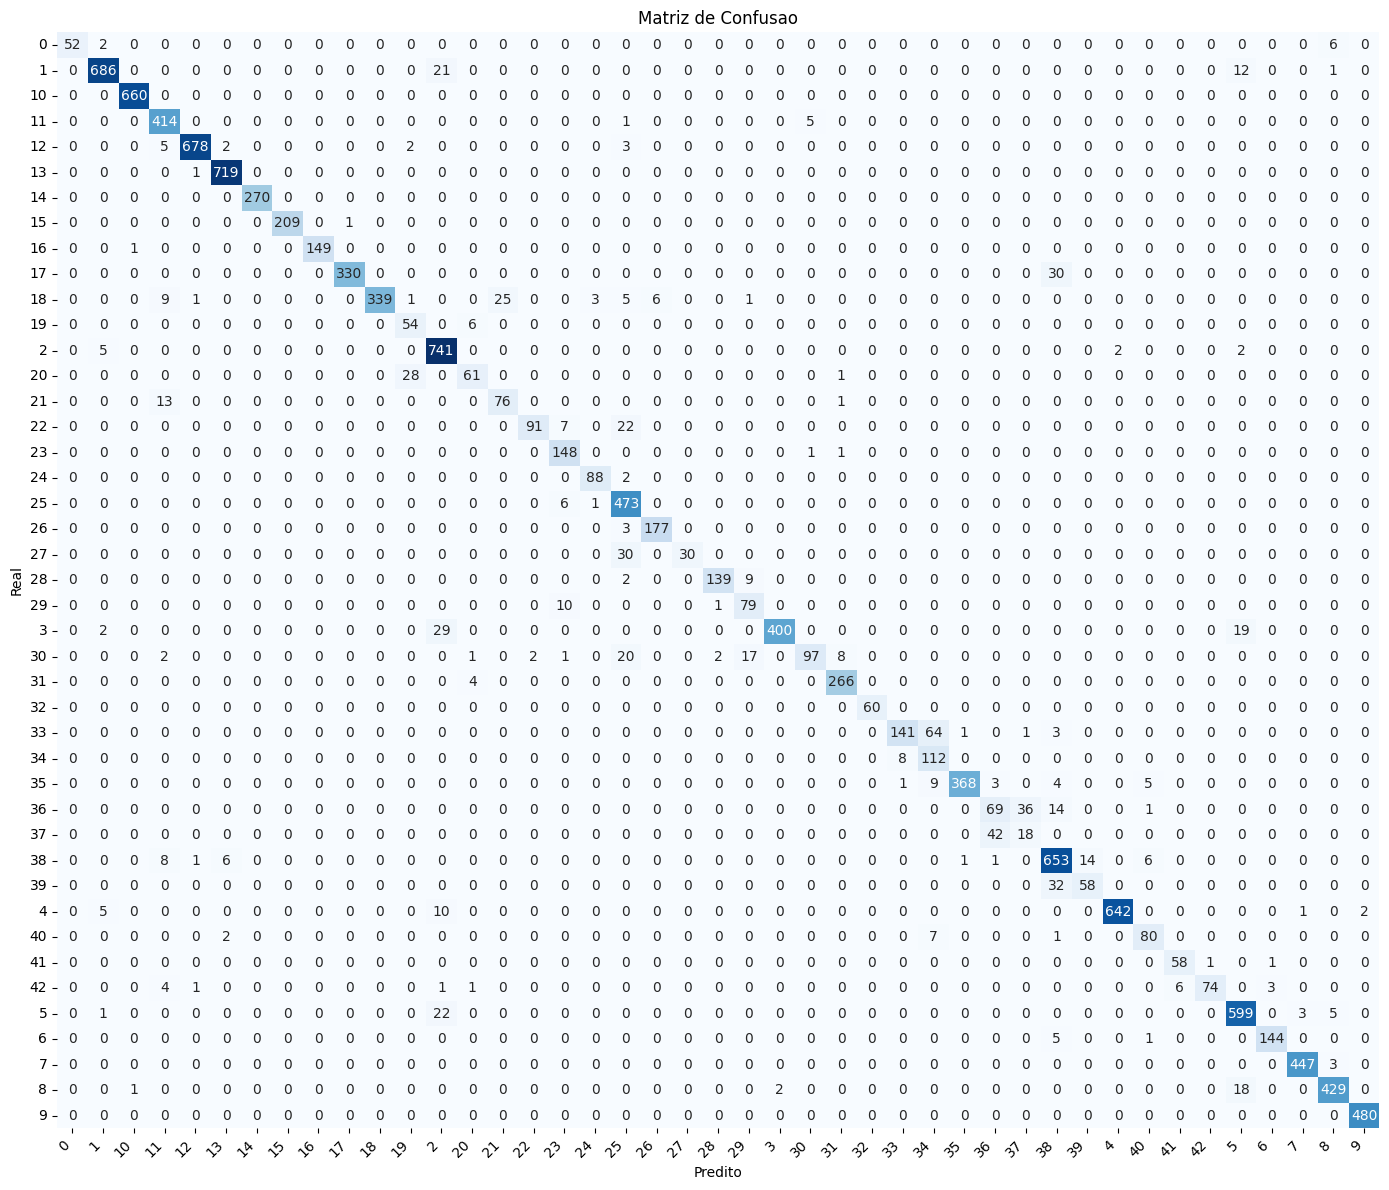

In [ ]:
# Matriz de confusao
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusao')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Predicoes corretas: 11858/12630
Predicoes incorretas: 772/12630


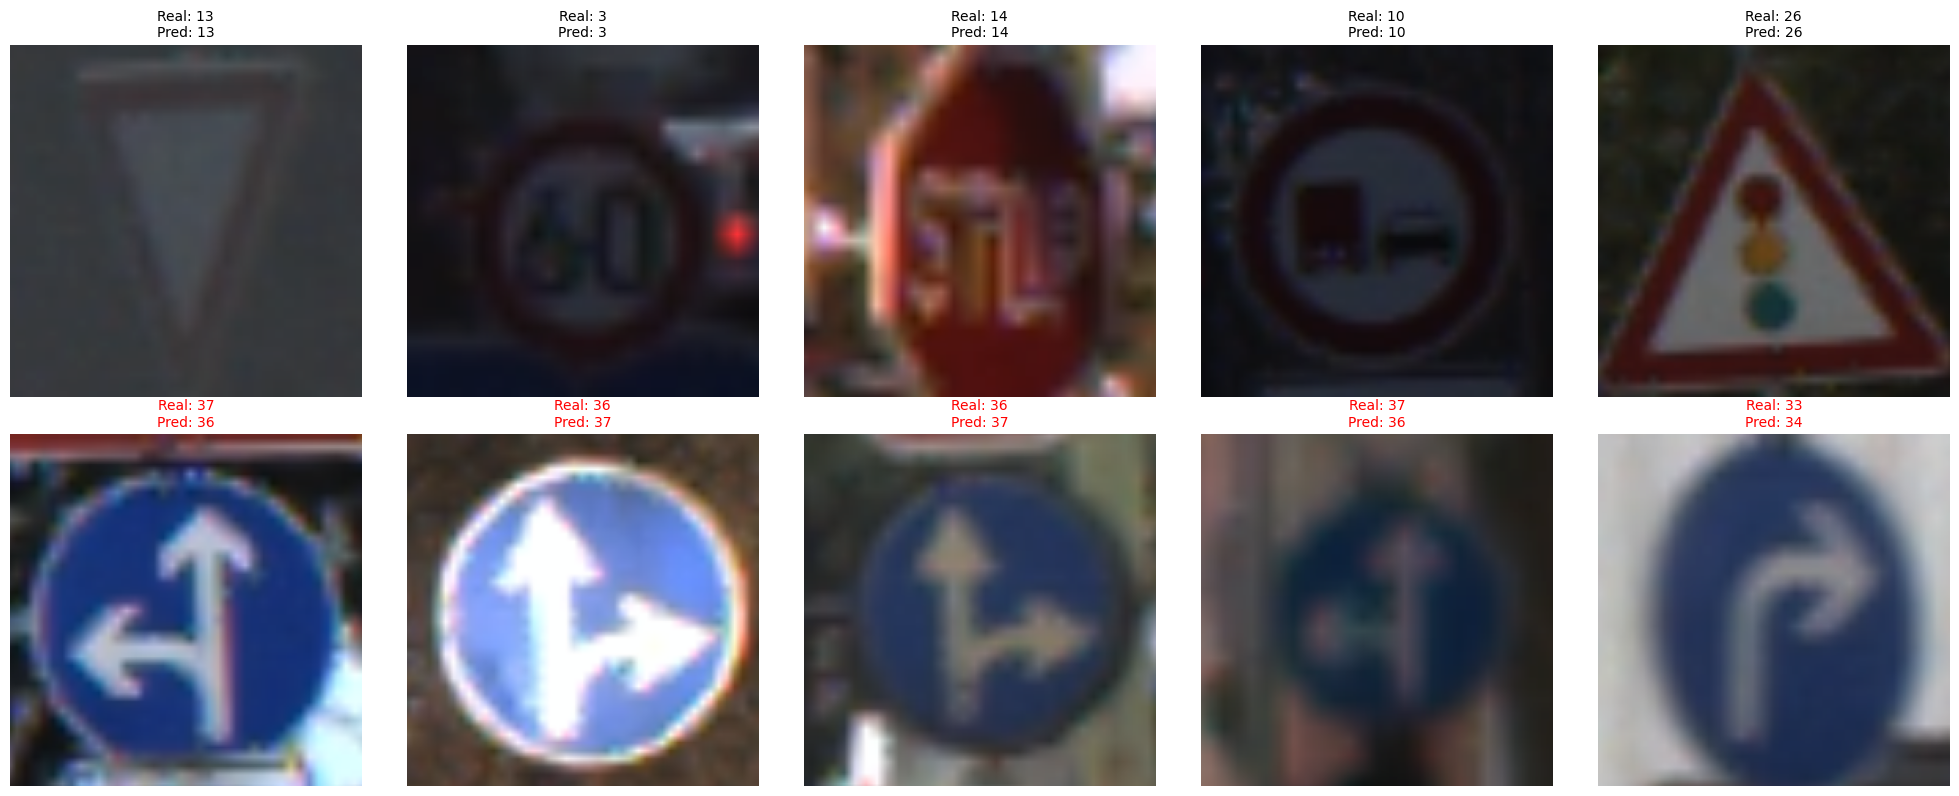

In [ ]:
# Exemplos de predicoes corretas e incorretas
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1)

correct_indices = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p == l]
incorrect_indices = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l]

print(f'Predicoes corretas: {len(correct_indices)}/{len(all_labels)}')
print(f'Predicoes incorretas: {len(incorrect_indices)}/{len(all_labels)}')

num_samples = min(5, len(correct_indices), len(incorrect_indices))

if num_samples > 0:
    selected_correct = random.sample(correct_indices, num_samples)
    selected_incorrect = random.sample(incorrect_indices, num_samples)

    fig, axes = plt.subplots(2, num_samples, figsize=(4 * num_samples, 8))

    for col, idx in enumerate(selected_correct):
        img, _ = val_dataset[idx]
        axes[0, col].imshow(denormalize(img))
        axes[0, col].set_title(f'Real: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}', fontsize=10)
        axes[0, col].axis('off')
    axes[0, 0].set_ylabel('CORRETAS', fontsize=12, fontweight='bold')

    for col, idx in enumerate(selected_incorrect):
        img, _ = val_dataset[idx]
        axes[1, col].imshow(denormalize(img))
        axes[1, col].set_title(f'Real: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}', fontsize=10, color='red')
        axes[1, col].axis('off')
    axes[1, 0].set_ylabel('INCORRETAS', fontsize=12, fontweight='bold', color='red')

    plt.tight_layout()
    plt.show()
else:
    print('Nao ha amostras suficientes para exibir exemplos.')

---
## 8. Salvamento dos Resultados

Nesta seção, salvamos em disco os principais resultados da avaliação para consulta futura:
- Gráficos de loss e acurácia
- Matriz de confusão
- Relatório de classificação (classification report)
- Exemplos de predições corretas e incorretas

In [ ]:
import os, zipfile
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

RESULTADOS_DIR = "resultados_mobilenetv2"
os.makedirs(RESULTADOS_DIR, exist_ok=True)

# 1. Graficos de loss e acuracia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [
    (ax1, 'loss', 'Loss'),
    (ax2, 'acc', 'Acuracia')
]:
    ax.plot(range(1, len(history[f'train_{metric}']) + 1), history[f'train_{metric}'], label='Treino')
    ax.plot(range(1, len(history[f'val_{metric}']) + 1), history[f'val_{metric}'], label='Validacao')
    ax.axvline(x=EPOCHS_FE, color='gray', linestyle='--', alpha=0.5, label='Fim FE / Inicio FT')
    ax.set_xlabel('Epoca')
    ax.set_ylabel(title)
    ax.set_title(f'{title} durante o treinamento')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS_DIR, "loss_acuracia.png"), dpi=300, bbox_inches="tight")
plt.close()

# 2. Matriz de confusao
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS_DIR, "matriz_confusao.png"), dpi=300, bbox_inches="tight")
plt.close()

# 3. Relatorio de classificacao
report = classification_report(all_labels, all_preds, target_names=class_names)
with open(os.path.join(RESULTADOS_DIR, "classification_report.txt"), "w", encoding="utf-8") as f:
    f.write(report)

# 4. Predicoes incorretas
erros_dir = os.path.join(RESULTADOS_DIR, "predicoes_incorretas")
os.makedirs(erros_dir, exist_ok=True)
for i, idx in enumerate(i for i in range(len(all_labels)) if all_labels[i] != all_preds[i]):
    img, _ = val_dataset[idx]
    plt.figure(figsize=(4,4))
    plt.imshow(denormalize(img))
    plt.title(f"Real: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}", color="red")
    plt.axis("off")
    plt.savefig(os.path.join(erros_dir, f"erro_{i}.png"), dpi=300, bbox_inches="tight")
    plt.close()

# 5. Predicoes corretas (ate 100)
acertos_dir = os.path.join(RESULTADOS_DIR, "predicoes_corretas")
os.makedirs(acertos_dir, exist_ok=True)
for i, idx in enumerate(i for i in range(len(all_labels)) if all_labels[i] == all_preds[i]):
    if i >= 100: break
    img, _ = val_dataset[idx]
    plt.figure(figsize=(4,4))
    plt.imshow(denormalize(img))
    plt.title(f"Classe: {class_names[all_labels[idx]]}", color="green")
    plt.axis("off")
    plt.savefig(os.path.join(acertos_dir, f"acerto_{i}.png"), dpi=300, bbox_inches="tight")
    plt.close()

# 6. Compactar resultados
with zipfile.ZipFile(f"{RESULTADOS_DIR}.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(RESULTADOS_DIR):
        for file in files:
            zf.write(os.path.join(root, file), os.path.relpath(os.path.join(root, file), RESULTADOS_DIR))

print(f"Resultados salvos em {RESULTADOS_DIR}/ e compactados em {RESULTADOS_DIR}.zip")

---
## 9. Salvamento e Download do Modelo

In [ ]:
# Salvar state_dict (leve, recomendado para carregamento futuro)
torch.save(model.state_dict(), 'classificador_placas.pth')
print('Modelo salvo como classificador_placas.pth (state_dict)')

# Salvar modelo completo (arquitetura + pesos)
torch.save(model, 'classificador_placas_completo.pth')
print('Modelo completo salvo como classificador_placas_completo.pth (para deploy)')

Modelo salvo como classificador_placas.pth (state_dict)
Modelo completo salvo como classificador_placas_completo.pth (para deploy)


In [ ]:
# Download para maquina local (apenas no Google Colab)
try:
    from google.colab import files
    print('Iniciando download...')
    files.download('classificador_placas.pth')
    print('Download concluido!')
except ImportError:
    print('Ambiente local detectado. Os arquivos estao em:')
    print(f'  {os.path.abspath("classificador_placas.pth")}')
    print(f'  {os.path.abspath("classificador_placas_completo.pth")}')

Iniciando download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download concluido!


## 10. Carregar Modelo Salvo e Reavaliar
**Pre-requisito:** ter os arquivos `classificador_placas.pth` ou `classificador_placas_completo.pth` no diretorio.

In [ ]:
cd /content/

/content


In [ ]:
# Setup necessario para reavaliacao
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import os, random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

NUM_CLASSES = 43
BATCH_SIZE = 32
DATA_DIR = "GTSRB"

val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "Test"), transform=val_transforms)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
class_names = val_dataset.classes
print(f"Classes: {len(class_names)}, Imagens: {len(val_dataset)}")

Dispositivo: cuda
Classes: 43, Imagens: 12630


In [ ]:
# Carregar modelo salvo
model = torch.load("classificador_placas_completo.pth", map_location=device, weights_only=False)
model.eval()
print("Modelo completo carregado.")

Modelo completo carregado.


Avaliando:   0%|          | 0/395 [00:00<?, ?it/s]


=== Relatorio de Classificacao ===
              precision    recall  f1-score   support

           0     1.0000    0.8667    0.9286        60
           1     0.9786    0.9528    0.9655       720
          10     0.9970    1.0000    0.9985       660
          11     0.9099    0.9857    0.9463       420
          12     0.9941    0.9826    0.9883       690
          13     0.9863    0.9986    0.9924       720
          14     1.0000    1.0000    1.0000       270
          15     1.0000    0.9952    0.9976       210
          16     1.0000    0.9933    0.9967       150
          17     0.9970    0.9167    0.9551       360
          18     1.0000    0.8692    0.9300       390
          19     0.6353    0.9000    0.7448        60
           2     0.8993    0.9880    0.9416       750
          20     0.8356    0.6778    0.7485        90
          21     0.7525    0.8444    0.7958        90
          22     0.9785    0.7583    0.8545       120
          23     0.8605    0.9867    0.9193  

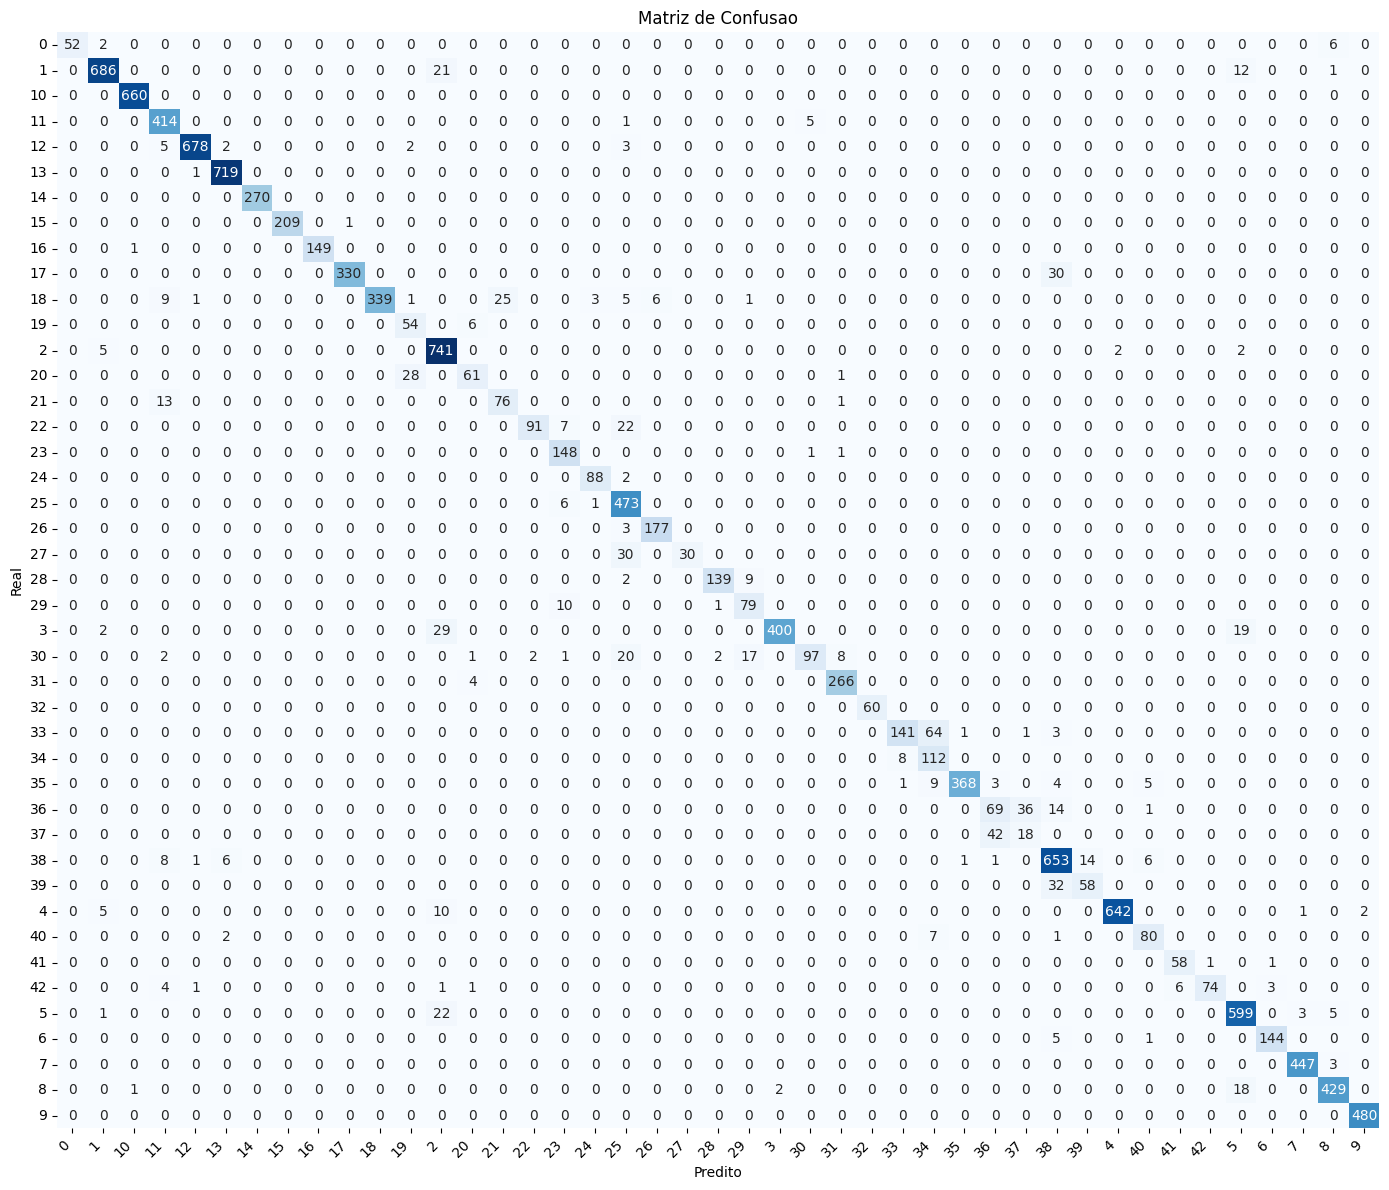

Predicoes corretas: 11858/12630
Predicoes incorretas: 772/12630


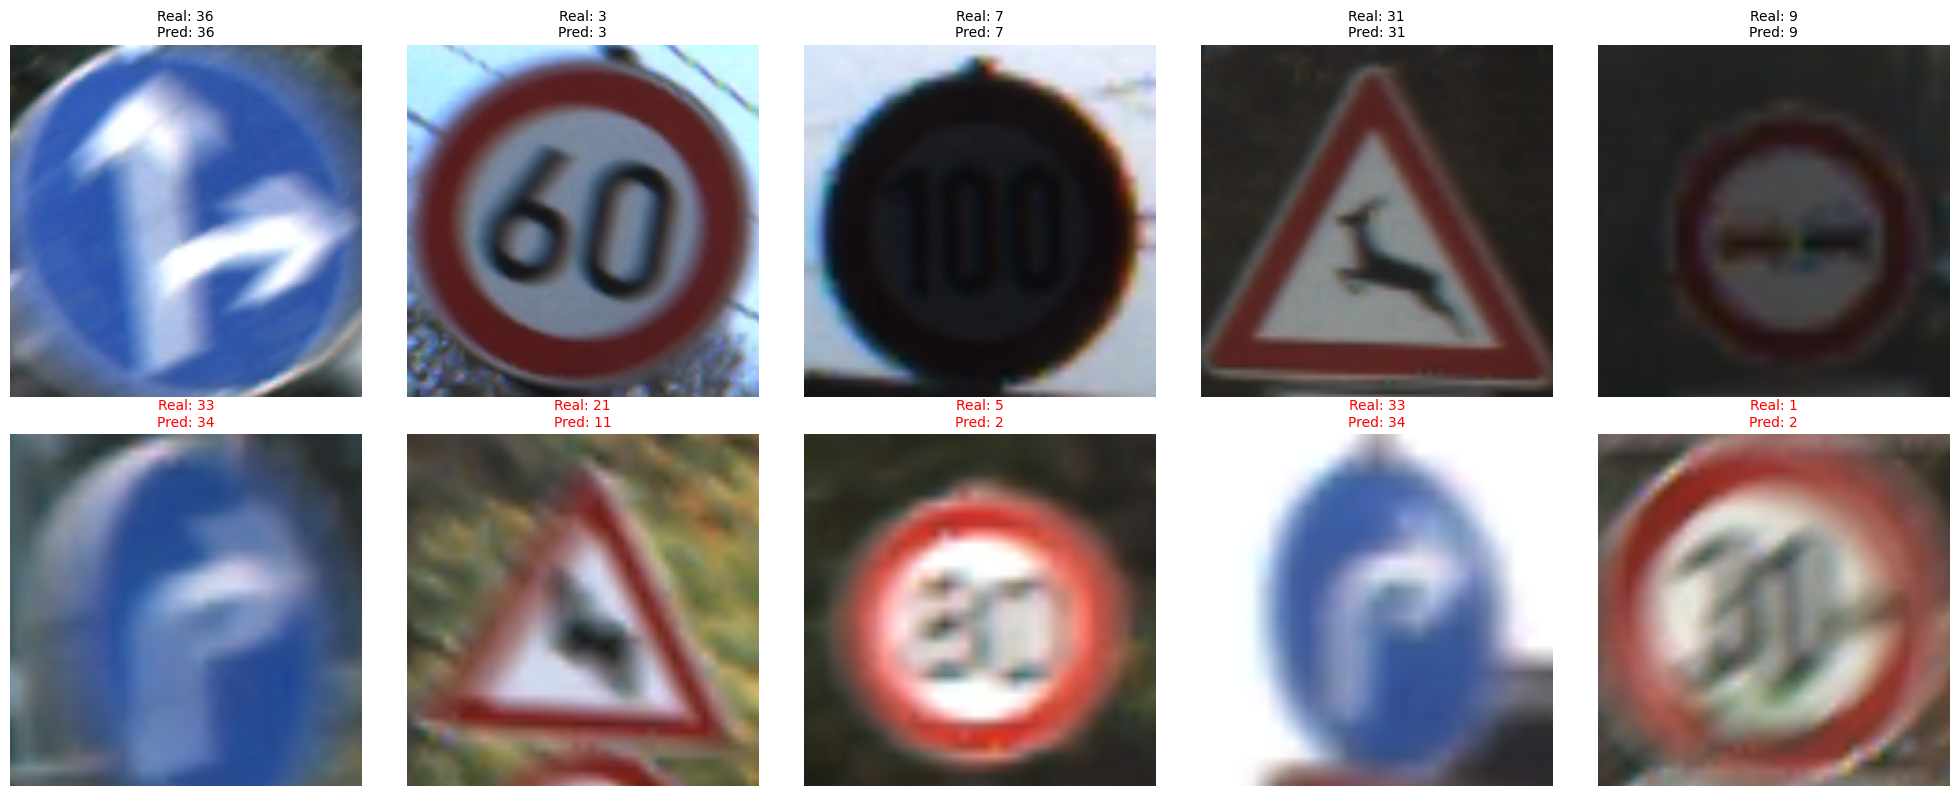

In [ ]:
# Reavaliacao: metricas e predicoes
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(val_loader, desc="Avaliando"):
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print('\n=== Relatorio de Classificacao ===')
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# Matriz de confusao
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusao')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Exemplos de predicoes corretas e incorretas
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1)

correct_indices = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p == l]
incorrect_indices = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l]

print(f'Predicoes corretas: {len(correct_indices)}/{len(all_labels)}')
print(f'Predicoes incorretas: {len(incorrect_indices)}/{len(all_labels)}')

num_samples = min(5, len(correct_indices), len(incorrect_indices))

if num_samples > 0:
    selected_correct = random.sample(correct_indices, num_samples)
    selected_incorrect = random.sample(incorrect_indices, num_samples)

    fig, axes = plt.subplots(2, num_samples, figsize=(4 * num_samples, 8))

    for col, idx in enumerate(selected_correct):
        img, _ = val_dataset[idx]
        axes[0, col].imshow(denormalize(img))
        axes[0, col].set_title(f'Real: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}', fontsize=10)
        axes[0, col].axis('off')
    axes[0, 0].set_ylabel('CORRETAS', fontsize=12, fontweight='bold')

    for col, idx in enumerate(selected_incorrect):
        img, _ = val_dataset[idx]
        axes[1, col].imshow(denormalize(img))
        axes[1, col].set_title(f'Real: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}', fontsize=10, color='red')
        axes[1, col].axis('off')
    axes[1, 0].set_ylabel('INCORRETAS', fontsize=12, fontweight='bold', color='red')

    plt.tight_layout()
    plt.show()
else:
    print('Nao ha amostras suficientes para exibir exemplos.')

In [ ]:
import os, zipfile
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

RESULTADOS_DIR = "resultados_mobilenetv2"
os.makedirs(RESULTADOS_DIR, exist_ok=True)

erros_dir = os.path.join(RESULTADOS_DIR, "predicoes_incorretas")
os.makedirs(erros_dir, exist_ok=True)
for i, idx in enumerate(i for i in range(len(all_labels)) if all_labels[i] != all_preds[i]):
    img, _ = val_dataset[idx]
    plt.figure(figsize=(4,4))
    plt.imshow(denormalize(img))
    plt.title(f"Real: {class_names[all_labels[idx]]}\nPred: {class_names[all_preds[idx]]}", color="red")
    plt.axis("off")
    plt.savefig(os.path.join(erros_dir, f"erro_{i}.png"), dpi=300, bbox_inches="tight")
    plt.close()

In [ ]:
# 6. Compactar resultados
with zipfile.ZipFile(f"{RESULTADOS_DIR}.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(RESULTADOS_DIR):
        for file in files:
            zf.write(os.path.join(root, file), os.path.relpath(os.path.join(root, file), RESULTADOS_DIR))